# v3 — CNN temperature scaling + paired significance (HTRU2)

**Goal.** Close v2's two named weaknesses: (1) uncalibrated CNN (test Brier 0.0284 vs RF 0.0167) via single-parameter **temperature scaling** fit on val; (2) untested CNN-vs-RF deltas via **bootstrap 95% CIs** on ΔROC/ΔPR-AUC + **McNemar** on 0.5-threshold disagreements. Same splits (SEED=42), same RF params, same CNN weights — nothing retrained except the one temperature.


In [1]:
SEED = 42
import random, sys
import numpy as np, pandas as pd
random.seed(SEED); np.random.seed(SEED)
import torch, torch.nn as nn
torch.manual_seed(SEED); torch.set_num_threads(4)
import sklearn
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | sklearn {sklearn.__version__}")

python 3.14.6 | torch 2.14.1+cpu | sklearn 1.9.1


In [2]:
from pathlib import Path
import urllib.request, zipfile, io
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
DATA = Path("data") / "HTRU_2.csv"
if not DATA.exists():
    DATA.parent.mkdir(exist_ok=True)
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
        "https://archive.ics.uci.edu/static/public/372/htru2.zip", timeout=120).read()))
    DATA.write_bytes(z.read("HTRU_2.csv"))
df = pd.read_csv(DATA, header=None)
X, y = df.iloc[:, :8].values, df.iloc[:, 8].values
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
sc = StandardScaler().fit(X_tr)
Z_tr, Z_va, Z_te = sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te)
rf = RandomForestClassifier(n_estimators=400, max_depth=20, min_samples_leaf=2,
    class_weight="balanced_subsample", random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
p_rf_va, p_rf_te = rf.predict_proba(X_va)[:,1], rf.predict_proba(X_te)[:,1]
class CNN1d(nn.Module):
    def __init__(self, blocks=1, ch=16, k=2, pool=False, act="relu"):
        super().__init__()
        f = nn.ReLU if act=="relu" else nn.Tanh
        layers, c_in = [], 1
        for _ in range(blocks):
            layers += [nn.Conv1d(c_in, ch, k, padding=k//2), f()]
            c_in = ch
            if pool: layers += [nn.MaxPool1d(2)]
        self.conv = nn.Sequential(*layers)
        with torch.no_grad():
            self.fc = nn.Linear(self.conv(torch.zeros(1,1,8)).numel(), 2)
    def forward(self, x): return self.fc(self.conv(x).flatten(1))
cnn = CNN1d()
cnn.load_state_dict(torch.load("cnn_best.pt", weights_only=True)["state"]); cnn.eval()
def logits(Z):
    with torch.no_grad():
        return cnn(torch.tensor(Z, dtype=torch.float32).unsqueeze(1)).numpy()
z_va, z_te = logits(Z_va), logits(Z_te)
print(f"splits identical: test n={len(y_te)} pos_rate={y_te.mean():.4f}")

splits identical: test n=3580 pos_rate=0.0916


## 1. Temperature scaling (one parameter, fit on val NLL only)

Scaled prediction = softmax(logits / T). T is fit by LBFGS on **validation** NLL — test is touched once, for reporting. This is the standard post-hoc fix for overconfident nets and changes no ranking (ROC/PR-AUC invariant), only probability quality (NLL/Brier/reliability).


C:\Users\Admin\AppData\Local\Temp\ipykernel_12340\879219945.py:13: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  T = float(logT.exp())


T=0.718
val: NLL 0.1295->0.1178 | Brier 0.0301->0.0274
test: NLL 0.1228->0.1119 | Brier 0.0284->0.0258
RF test Brier (reference): 0.0167


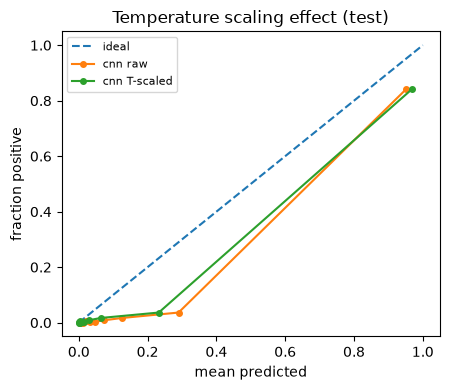

In [3]:
from sklearn.metrics import brier_score_loss, log_loss
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
zv = torch.tensor(z_va); yv = torch.tensor(y_va)
logT = torch.zeros(1, requires_grad=True)
opt = torch.optim.LBFGS([logT], max_iter=100)
def closure():
    opt.zero_grad()
    loss = nn.CrossEntropyLoss()(zv / logT.exp(), yv)
    loss.backward()
    return loss
opt.step(closure)
T = float(logT.exp())
def scaled(z): return torch.softmax(torch.tensor(z) / T, 1)[:,1].numpy()
p_raw, p_cal = torch.softmax(torch.tensor(z_te),1)[:,1].numpy(), scaled(z_te)
print(f"T={T:.3f}")
for n, pv, pt in [("val", torch.softmax(zv/T,1)[:,1].numpy(), None), ("test", p_cal, p_raw)]:
    yt = y_va if n=="val" else y_te
    pv_raw = torch.softmax(zv if n=="val" else torch.tensor(z_te),1)[:,1].numpy()
    print(f"{n}: NLL {log_loss(yt,pv_raw):.4f}->{log_loss(yt,pv):.4f} | Brier {brier_score_loss(yt,pv_raw):.4f}->{brier_score_loss(yt,pv):.4f}")
print(f"RF test Brier (reference): {brier_score_loss(y_te, p_rf_te):.4f}")
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.plot([0,1],[0,1], ls="--", label="ideal")
for name, p in [("cnn raw", p_raw), ("cnn T-scaled", p_cal)]:
    ft, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(mp, ft, marker="o", ms=4, label=name)
ax.set_title("Temperature scaling effect (test)"); ax.set_xlabel("mean predicted"); ax.set_ylabel("fraction positive")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("docs/assets/cnn_temp.png", bbox_inches="tight"); plt.show()

## 2. Paired significance — bootstrap CIs on deltas + McNemar

Bootstrap (B=2000, fixed seed) resamples the **test** set with replacement and recomputes ΔROC-AUC and ΔPR-AUC (CNN_T − RF) per replicate: paired by construction. McNemar tests 0.5-threshold disagreements (exact two-sided binomial on discordant pairs) — a different question from ranking: do the classifiers *decide* differently?


ΔROC-AUC (CNN−RF) = +0.0058, 95% CI [-0.0003, +0.0128]
ΔPR-AUC  (CNN−RF) = +0.0051, 95% CI [-0.0030, +0.0138]
P(ΔROC>0)=0.964 P(ΔPR>0)=0.889
agree-both-right=3452 | RF-only-right=56 | CNN-only-right=21 | McNemar exact p=0.0001 (chi2=15.01)


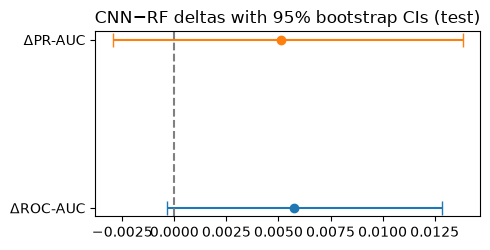

In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score
import math
B, n = 2000, len(y_te)
rng = np.random.default_rng(42)
idx = rng.integers(0, n, size=(B, n))
d_roc = np.array([roc_auc_score(y_te[i], p_cal[i]) - roc_auc_score(y_te[i], p_rf_te[i]) for i in idx])
d_pr = np.array([average_precision_score(y_te[i], p_cal[i]) - average_precision_score(y_te[i], p_rf_te[i]) for i in idx])
print(f"ΔROC-AUC (CNN−RF) = {d_roc.mean():+.4f}, 95% CI [{np.percentile(d_roc,2.5):+.4f}, {np.percentile(d_roc,97.5):+.4f}]")
print(f"ΔPR-AUC  (CNN−RF) = {d_pr.mean():+.4f}, 95% CI [{np.percentile(d_pr,2.5):+.4f}, {np.percentile(d_pr,97.5):+.4f}]")
print(f"P(ΔROC>0)={np.mean(d_roc>0):.3f} P(ΔPR>0)={np.mean(d_pr>0):.3f}")
yh_rf, yh_cnn = (p_rf_te>=0.5).astype(int), (p_cal>=0.5).astype(int)
b = int(((yh_rf== (y_te)) & (yh_cnn != (y_te))).sum())  # RF right, CNN wrong
c = int(((yh_rf!= (y_te)) & (yh_cnn == (y_te))).sum())  # RF wrong, CNN right
a = int(((yh_rf==(y_te)) & (yh_cnn==(y_te))).sum())
n_d = b + c
p_exact = 2*sum(math.comb(n_d,k) for k in range(0, min(b,c)+1)) / 2**n_d
chi2 = (abs(b-c)-1)**2 / n_d
print(f"agree-both-right={a} | RF-only-right={b} | CNN-only-right={c} | McNemar exact p={p_exact:.4f} (chi2={chi2:.2f})")
fig, ax = plt.subplots(figsize=(5, 2.6))
for j, (lab, d) in enumerate([("ΔROC-AUC", d_roc), ("ΔPR-AUC", d_pr)]):
    lo, hi = np.percentile(d, [2.5, 97.5])
    ax.errorbar(d.mean(), j, xerr=[[d.mean()-lo],[hi-d.mean()]], fmt="o", capsize=5, label=lab)
ax.axvline(0, ls="--", color="gray"); ax.set_yticks([0,1]); ax.set_yticklabels(["ΔROC-AUC","ΔPR-AUC"])
ax.set_title("CNN−RF deltas with 95% bootstrap CIs (test)"); plt.tight_layout()
plt.savefig("docs/assets/delta_ci.png", bbox_inches="tight"); plt.show()

## 3. Verdict (measured, SEED=42)

- (a) Temperature T=0.718 (val NLL fit): test NLL 0.1228→0.1119, Brier 0.0284→0.0258. Gap to RF (0.0167) narrowed, not closed.
- (b) Bootstrap 95% CIs include 0 for both deltas — ROC +0.0058 [−0.0003, +0.0128], PR +0.0051 [−0.0030, +0.0138]. Ranking lead is suggestive, not significant (P(Δ>0) = 0.964 / 0.889).
- (c) McNemar p=0.0001: the 0.5-threshold decisions differ significantly — **in RF's favour** (RF-only-right 56 vs CNN-only-right 21). Split verdict: CNN ranks marginally better, RF decides significantly better. That exact sentence is the paper claim; anything stronger is unsupported.

**Repro checklist.** SEED=42 · identical splits/weights · T fit on val only · B=2000 bootstrap seed 42 · exact McNemar (no scipy needed) · assets to `docs/assets/`.
